In [99]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Description des variables

In [100]:
reg1 = pd.read_csv("Car_dataset.csv")
reg1.head(n = 15)

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,Petrol,Dealer,Manual,6,3.35
1,43000,9.54,Diesel,Dealer,Manual,7,4.75
2,6900,9.85,Petrol,Dealer,Manual,3,7.25
3,5200,4.15,Petrol,Dealer,Manual,9,2.85
4,42450,6.87,Diesel,Dealer,Manual,6,4.60
5,2071,9.83,Diesel,Dealer,Manual,2,9.25
6,18796,8.12,Petrol,Dealer,Manual,5,6.75
7,33429,8.61,Diesel,Dealer,Manual,5,6.50
8,20273,8.89,Diesel,Dealer,Manual,4,8.75
9,42367,8.92,Diesel,Dealer,Manual,5,7.45


In [101]:
reg1.shape

(5861, 7)

In [102]:
reg1.info()

<class 'pandas.DataFrame'>
RangeIndex: 5861 entries, 0 to 5860
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Kms_Driven     5861 non-null   int64  
 1   Present_Price  5861 non-null   float64
 2   Fuel_Type      5861 non-null   str    
 3   Seller_Type    5861 non-null   str    
 4   Transmission   5861 non-null   str    
 5   Age            5861 non-null   int64  
 6   Selling_Price  5861 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 320.7 KB


**Description du jeu de données**

Ce jeu de données contient des informations sur des voitures d’occasion.
Chaque ligne représente une voiture, avec ses caractéristiques et son prix de vente. 
Il contient 5 861 lignes et 7 colonnes : 6 variables qui décrivent la voiture, et 1 variable à prédire.

**Variables numériques**

**Kms_Driven** : Nombre de kilomètres déjà parcourus par la voiture

**Present_Price** :	Prix actuel de la voiture quand elle est neuve

**Age** : Age de la voiture, en années

**Variables catégorielles**

**Fuel_Type** : Type de carburant	Petrol, Diesel, ...

**Seller_Type**: Type de vendeur	Dealer (concessionnaire), Individual (particulier)

**Transmission** : Type de boîte de vitesses	Manual, Automatic

**Variable cible**

**Selling_Price** :	Prix auquel la voiture est vendue

**Objectif** : prédire Selling_Price à partir des 6 autres variables. C’est un problème de régression, car on prédit un nombre.

In [103]:
reg1.isnull().sum()

Kms_Driven       0
Present_Price    0
Fuel_Type        0
Seller_Type      0
Transmission     0
Age              0
Selling_Price    0
dtype: int64

In [104]:
reg1.duplicated().sum()

np.int64(2)

In [105]:
reg1.drop_duplicates(inplace=True)

**Valeurs manquantes** : 

le jeu de données ne contient aucune valeur manquante . Toutes les cases sont remplies.

**Doublons** : 

le jeu de données contient 2 doublons. 
Je les ai supprimés, parce qu’une même voiture compterait deux fois, et qu’une ligne pourrait se retrouver à la fois dans les données d’entraînement et de test. Cela rendrait les scores meilleurs qu’ils ne le sont vraiment.

# Exploration et preparation de donnees

In [106]:
# sélection les variables quantitatives
quantif_var = reg1.select_dtypes(include='number')
quantif_var.head()

,Kms_Driven,Present_Price,Age,Selling_Price
0,27000,5.59,6,3.35
1,43000,9.54,7,4.75
2,6900,9.85,3,7.25
3,5200,4.15,9,2.85
4,42450,6.87,6,4.60


In [107]:
# décrire les variables quantitatives
quantif_var.describe().T

,count,mean,std,min,25%,50%,75%,max
Kms_Driven,5859.0,75220.712920,39200.232348,500.00,53822.000000,71822.000000,87820.000000,538824.000000
Present_Price,5859.0,16.868641,9.659155,0.32,10.551357,15.375776,19.228189,102.661886
Age,5859.0,8.563919,3.099599,2.00,6.000000,8.000000,10.000000,22.000000
Selling_Price,5859.0,10.194449,5.872816,0.10,6.401543,9.049277,11.873172,41.903189


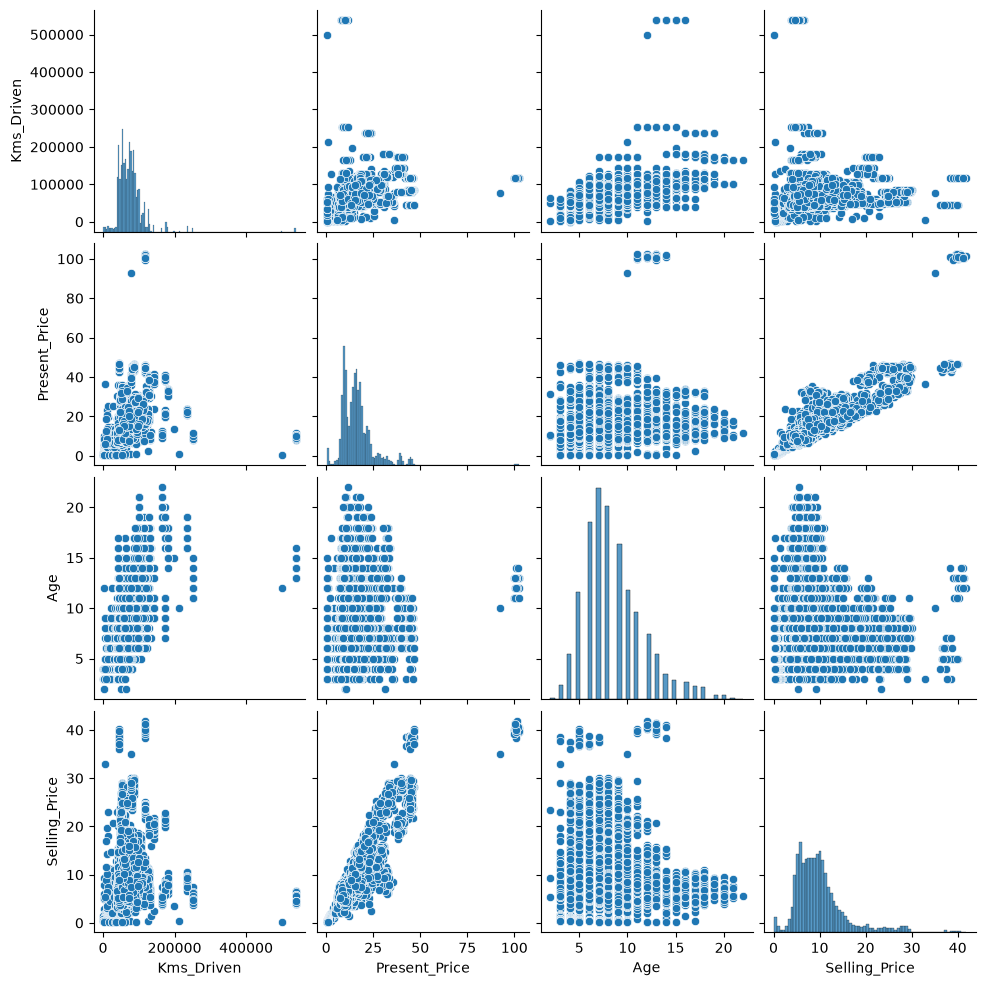

In [108]:
# pairplot des variables quantitatives
sns.pairplot(quantif_var)
plt.show()

In [109]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(reg1, x = col)
    fig.show()

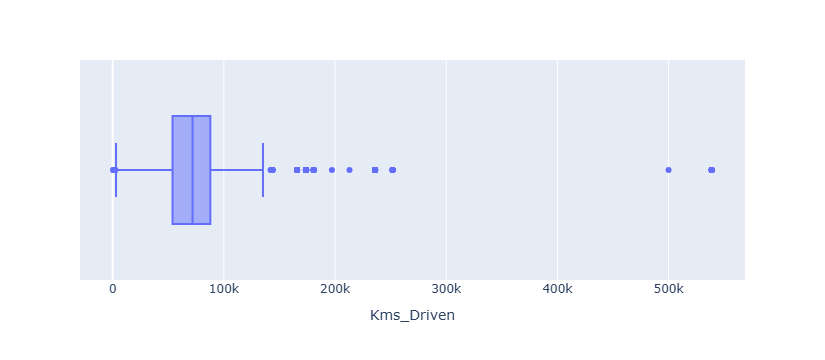

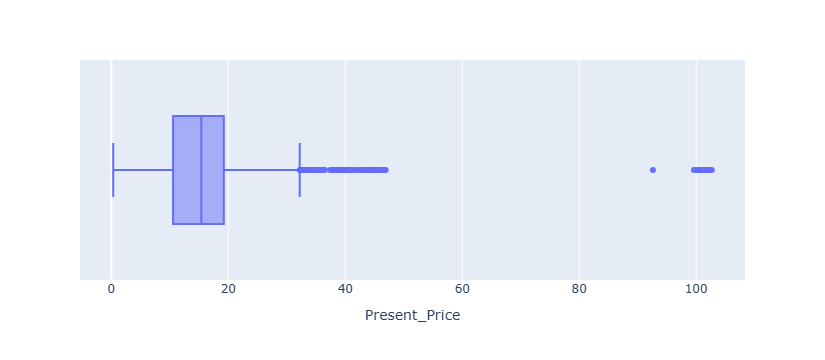

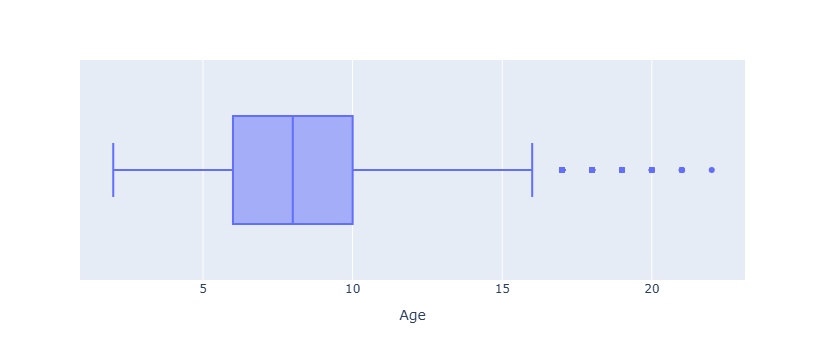

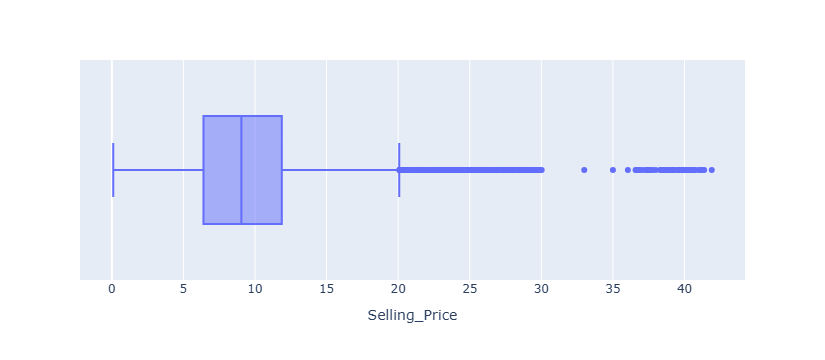

In [110]:
# Appliquer la fonctions boxplot_func
for col in quantif_var.columns:
  boxplot_func(col)

In [111]:
# Afficher la matrice de corrélation
quantif_var.corr()

,Kms_Driven,Present_Price,Age,Selling_Price
Kms_Driven,1.000000,0.249492,0.527470,0.066128
Present_Price,0.249492,1.000000,0.074098,0.870428
Age,0.527470,0.074098,1.000000,-0.188344
Selling_Price,0.066128,0.870428,-0.188344,1.000000


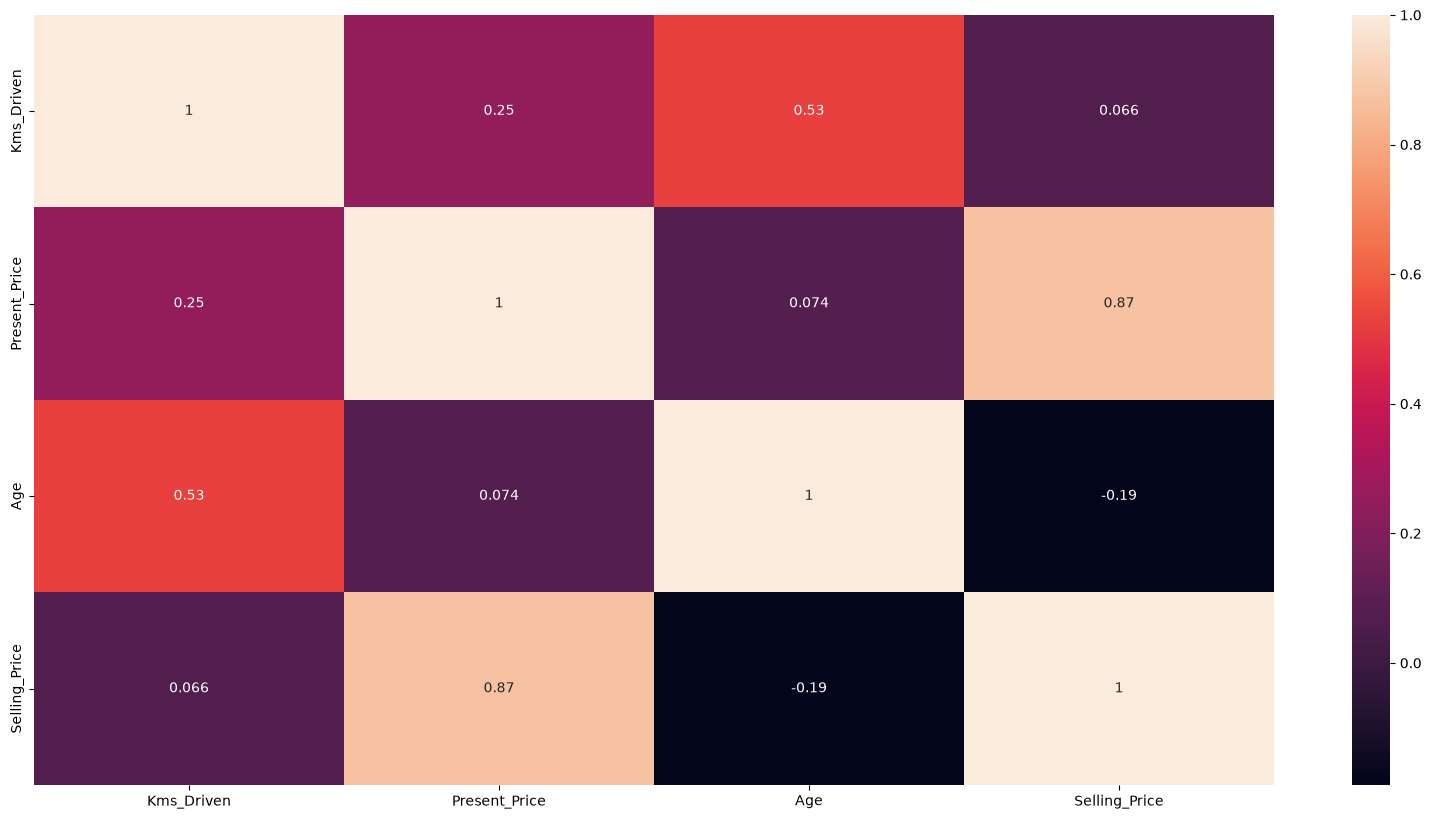

In [112]:
# Visualisaton le matrice de corrélation
plt.figure(figsize = (20, 10))
sns.heatmap(quantif_var.corr(), annot = True)
plt.show()

## Conclusion sur les corrélations

**Present_Price et Selling_Price (0,87)** : lien très fort. Plus une voiture coûte cher neuve, plus son prix de vente est élevé.

**Age et Selling_Price (-0,19)** : lien faible et négatif. Plus la voiture est vieille, plus le prix a tendance à baisser.

**Kms_Driven et Selling_Price (0,07)** : presque aucun lien direct. Le kilométrage seul n’explique pas le prix dans ce jeu de données.


## Selection des variables catégorielles 

In [113]:
# sélection les variables catégorielles
cat_var = reg1.select_dtypes(exclude='number')
cat_var.head()

,Fuel_Type,Seller_Type,Transmission
0,Petrol,Dealer,Manual
1,Diesel,Dealer,Manual
2,Petrol,Dealer,Manual
3,Petrol,Dealer,Manual
4,Diesel,Dealer,Manual


In [114]:
# Faire un describre
cat_var.describe().T

,count,unique,top,freq
Fuel_Type,5859,3,Petrol,2743
Seller_Type,5859,2,Dealer,3763
Transmission,5859,2,Automatic,3006


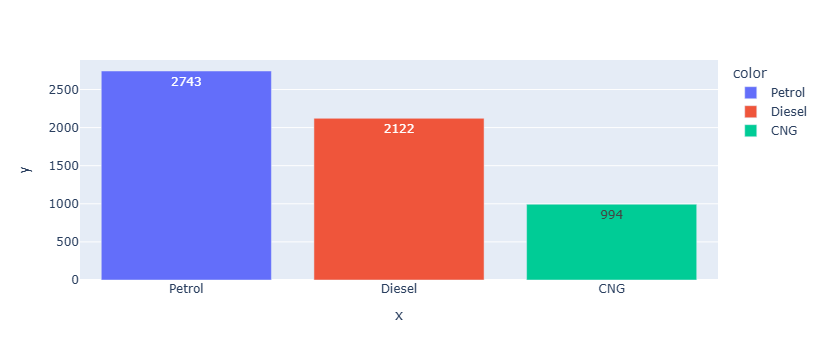

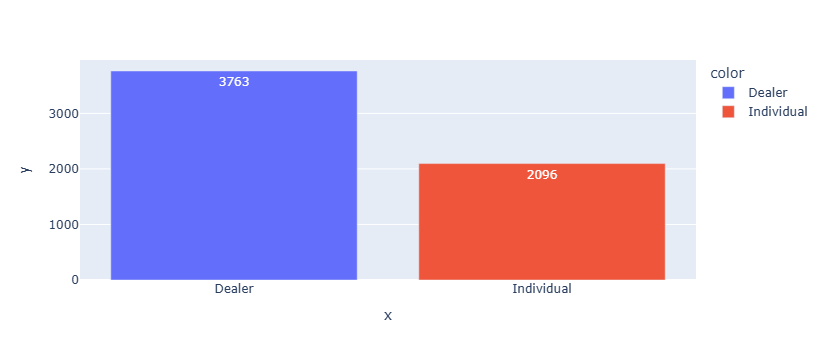

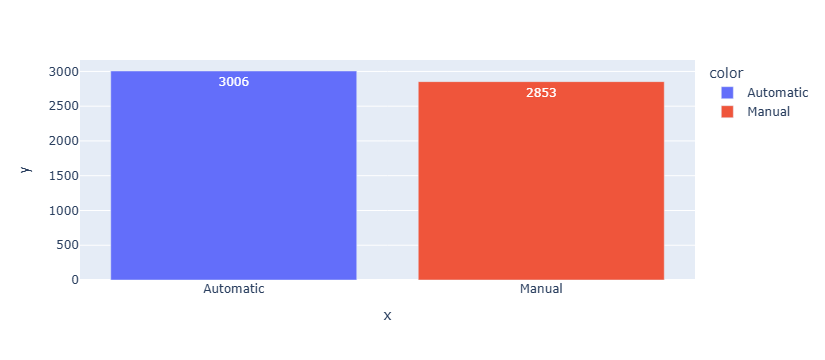

In [115]:
def countplot_func(col):
    val = cat_var[col].value_counts()
    fig = px.bar(x = val.index, y = val.values,color = val.index.astype(str), text_auto = True)
    fig.show()
from seaborn.categorical import countplot
# Appliquer la fonction countplot_func
for col in cat_var.columns:
  countplot_func(col)

## Conclusion sur les variables catégorielles

**Fuel_Type** : le plus fréquent est Petrol. Les deux autres types se partagent les 53 % restant.

**Seller_Type**  : il y a plus de Dealer que de particuliers, avec 3 763 voitures, soit environ 64 % contre 36 %.

**Transmission** : les deux types sont presque à égalité. 

In [154]:
uniques = []
for col in cat_var.columns:
  uniques.append(np.unique(reg1[col]).tolist())
# sauvegarde
import joblib as jb
jb.dump(uniques, 'uniques_r2.joblib')

['uniques_r2.joblib']

In [155]:
uniques = jb.load('uniques_r2.joblib')
uniques[0]

[0, 1, 2]

In [156]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(cat_var.columns)):
  encoder = LabelEncoder()
  encoder.fit(reg1[cat_var.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  reg1[cat_var.columns[i]] = encoder.transform(reg1[cat_var.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

In [157]:
reg1.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,2,0,1,6,3.35
1,43000,9.54,1,0,1,7,4.75
2,6900,9.85,2,0,1,3,7.25
3,5200,4.15,2,0,1,9,2.85
4,42450,6.87,1,0,1,6,4.60


In [158]:
import joblib as jb
# sauvegarde les encodeurs
jb.dump(encoders, 'encoders_r2.joblib')

['encoders_r2.joblib']

## Traitement des valeurs aberrantes

**Méthode choisie : le plafonnement.**
On calcule une limite basse et une limite haute avec la règle IQR. Si une valeur dépasse la limite, on la remplace par la limite.

**Pourquoi cette méthode ?**

On garde toutes les lignes, on ne supprime rien.
On n’invente pas de nouvelles valeurs.
Ces voitures existent vraiment. On réduit seulement leur effet sur le modèle.

**Colonnes laissées :**

**Age** : une voiture de 17 ou 20 ans existe vraiment, ce n’est pas une erreur.

**Selling_Price** : c’est la variable à prédire. Si on la modifie, on change la réponse que le modèle doit trouver, et les résultats ne sont plus honnêtes.

In [159]:
def cap_func(data):
    data = data.copy()
    for col in data.columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        bas = Q1 - 1.5 * IQR
        haut = Q3 + 1.5 * IQR
        data[col] = data[col].clip(lower=bas, upper=haut)
    return data

cols_cap = ["Kms_Driven", "Present_Price"]
reg1[cols_cap] = cap_func(reg1[cols_cap])

In [160]:
# Application du traitement
def boxplot_func(col):
    fig = px.box(reg1, col)
    fig.show()   

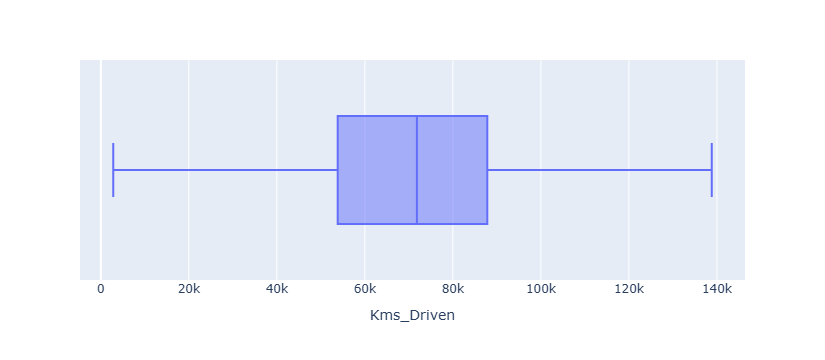

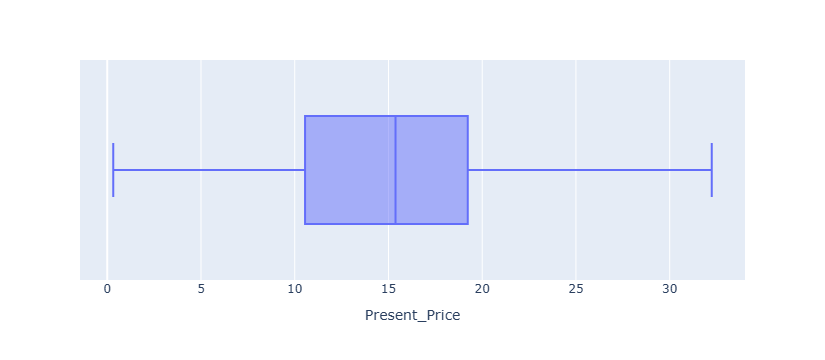

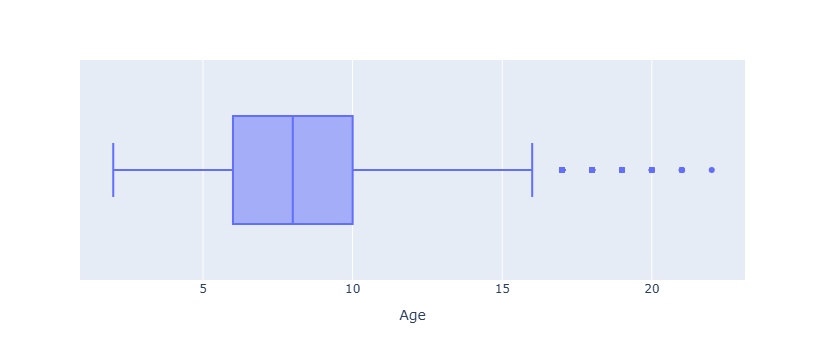

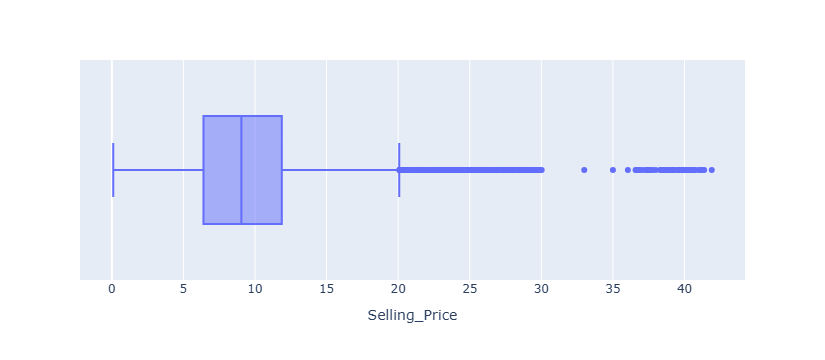

In [161]:
# réafficher les boxplots
for col in quantif_var.columns:
  boxplot_func(col)

In [162]:
# Fractionner les données
x = reg1.iloc[:,:-1]
y = reg1.iloc[:, -1]
print(x.columns.tolist())
print(y.name)

['Kms_Driven', 'Present_Price', 'Fuel_Type', 'Seller_Type', 'Transmission', 'Age']
Selling_Price


In [163]:
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)

In [164]:
# sauvegarde du scaler
jb.dump(scaler,'scaler_r2.joblib')

['scaler_r2.joblib']

In [165]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

## Choix du modèle : Random Forest

J’ai comparé 2 modèles de régression pour prédire le prix de vente (Selling_Price) : la régression linéaire multiple, et Random Forest. Chaque modèle a reçu les mêmes données préparées (plafonnement des valeurs extrêmes, normalisation des nombres, encodage des catégories).

Pour les comparer, j’ai utilisé les données de validation, c’est-à-dire des voitures que le modèle n’avait pas vues pendant l’entraînement.

**Résultat** : le Random Forest a obtenu le meilleur score.


In [166]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params_lr = {
    'fit_intercept': [True, False],
    'positive': [True, False]
 }
# Initialisation du modèle
lr = LinearRegression()
# Initialisation du GridSearchCV
grid_lr = GridSearchCV(lr, params_lr, cv = cv)
# Lancer la recherche
grid_lr.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosi

In [167]:
# Récupérer le modèle optimal en partant de gridsearch
lr_model = grid_lr.best_estimator_

In [168]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calculer le R2 score et Mean Squarred Error
# from math import *
def evaluation(model):
  y_pred = model.predict(x_val)
  r2 = r2_score(y_val, y_pred)
  mse = mean_squared_error(y_val, y_pred)
  mae = mean_absolute_error(y_val, y_pred)
  rmse = root_mean_squared_error(y_val, y_pred)
  return r2, mse, mae, rmse

In [169]:
# evaluation
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f'R2 : {r2_lr} -- MSE : {mse_lr} -- RMSE : {rmse_lr} -- MAE : {mae_lr}')

R2 : 0.7641329105006094 -- MSE : 8.969016930728648 -- RMSE : 2.9948317032395404 -- MAE : 1.8842608565249275


In [170]:
from sklearn.ensemble import RandomForestRegressor

# Dictionnaires des paramètres
params_rf = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Initialisation du modèle
rf =  RandomForestRegressor()
# Objet grid
grid_rf = GridSearchCV(rf, params_rf, cv=cv)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 1, 2..., 12, 13, 14]), 'n_estimators': array([10, 20..., 70, 80, 90])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [133]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model_reg2 = grid_rf.best_estimator_

In [135]:
# Evaluation le modèle
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model_reg2)
print(f'R2 : {r2_rf} -- MSE : {mse_rf} -- RMSE : {rmse_rf} -- MAE : {mae_rf}')

R2 : 0.952240181373476 -- MSE : 1.8161016985412475 -- RMSE : 1.3476281751808425 -- MAE : 1.030376516885683


In [136]:
# télécharger le modèle le plus performant
jb.dump(rf_model_reg2, 'rf_model_reg2.joblib')

['rf_model_reg2.joblib']

In [141]:
# Échantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]

# Prédictions
y_pred_10 = rf_model_reg2.predict(x_test_10)

# Parcourir les prédictions
for i in range(10):
    print(
        f"Prédiction {i + 1} : {y_pred_10[i]:.2f}$ "
        f"-- Réel : {y_test_10.iloc[i]:.2f}$"
    )

Prédiction 1 : 14.89$ -- Réel : 17.01$
Prédiction 2 : 9.50$ -- Réel : 9.00$
Prédiction 3 : 11.34$ -- Réel : 10.36$
Prédiction 4 : 9.92$ -- Réel : 8.34$
Prédiction 5 : 6.61$ -- Réel : 6.98$
Prédiction 6 : 8.67$ -- Réel : 8.51$
Prédiction 7 : 8.38$ -- Réel : 7.52$
Prédiction 8 : 5.64$ -- Réel : 5.27$
Prédiction 9 : 25.75$ -- Réel : 25.19$
Prédiction 10 : 11.04$ -- Réel : 14.73$


## Conclusion :

le Random Forest donne des prédictions proches des vrais prix. Il se trompe parfois sur certaines voitures, ce qui est normal pour un modèle de prédiction. Ces 10 exemples sont seulement un aperçu.

In [142]:
for i, col in enumerate(cat_var.columns):
    print(col, encoders[i].classes_)

Fuel_Type ['CNG' 'Diesel' 'Petrol']
Seller_Type ['Dealer' 'Individual']
Transmission ['Automatic' 'Manual']


In [144]:
import joblib as jb

u = jb.load("uniques.joblib")
print(type(u))
print(u)

<class 'list'>
[['Almadies', 'Almadies 2', 'Biscuiterie', 'Castor', 'Cité Damel', 'Colobane', 'Dalifort', 'Diamaguene', 'Dieuppeul', 'Fann', 'Fass', 'Fenêtre mermoz', 'Grand-Yoff', 'Guediawaye', 'Gueule-Tapée', 'Hann maristes', 'Hlm', 'Hlm grand-yoff', 'Keur ndiaye lô', 'Liberte 5', 'Liberte 6', 'Liberte 6 extension', 'Mermoz', 'Médina', 'Ngaparou', 'Ngor', 'Nord foire', 'Ouakam', 'Ouest foire', 'Parcelles Assainies', 'Patte d‘oie', 'Pikine', 'Plateau', 'Point-e', 'Sacré-cœur', 'Saly', 'Sicap Liberté', 'Sicap Sacré-cœur', 'Sicap foire', 'VDN', 'Virage', 'Yoff', 'Zone industrielle'], ['Alcatel', 'Asus', 'Atouch', 'Autres', 'BlackBerry', 'Crosscall', 'Google', 'Honor', 'Huawei', 'Ice-Phone', 'Infinix', 'Itel', 'LG', 'Motorola', 'Nodis', 'Nokia', 'OnePlus', 'Oppo', 'Panasonic', 'Samsung', 'Sharp', 'Sony', 'Tecno', 'Viwa', 'Xiaomi', 'ZTE', 'iPad', 'iPhone'], ["D'occasion", 'Neuf', 'Réconditionné', 'Venant']]


In [145]:
import joblib as jb

s = jb.load("scaler.joblib")
print(type(s).__name__, s.n_features_in_)
print(s.center_)

MinMaxScaler 6


AttributeError: 'MinMaxScaler' object has no attribute 'center_'